# Granularities of Altered Surface Area
This analysis notebook investigates the distribution of mask to image surface area ratios, and determine a set number of "bins" that represent various magnitudes of diffusion model augmentation of an image.

In [1]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import json
import ipdb
import matplotlib.pyplot as plt
import random
from PIL import Image

In [2]:
NUM_BINS = 5
METADATA = "/data/jkruk3/Diffm_FakeImage_Dataset_5k/metadata_5k.json"
ROOT_DIR = "/data/jkruk3/Diffm_FakeImage_Dataset_5k"

### Helper Functions

In [54]:
def create_even_bins(all_ratios, n_bins):
    """
    Create bins of equal data size.
    """
    all_ratios.sort()
    data_per_bin = int(len(all_ratios)/ n_bins) + 1
    
    bins = []
    for i in range(n_bins):
        bins.append([])
        
    for j in range(len(all_ratios)):
        ratio = all_ratios[j]
        i = int(j/data_per_bin)
        bins[i].append(ratio)
            
    return bins

### Analysis

In [3]:
with open(METADATA, 'r') as jf:
    data = json.load(jf)

In [4]:
all_ratios = []

for key, meta in data.items():
    for obj in meta['objects']:
        all_ratios.append(obj['ratio'])
        
print(f"Number of masks in set:   {len(all_ratios)}")

Number of masks in set:   45261


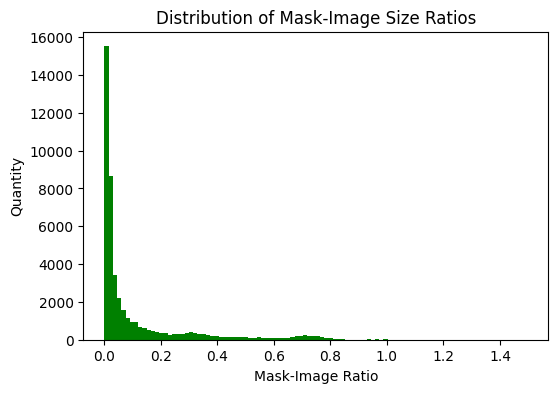

In [5]:
fig, ax = plt.subplots(figsize =(6,4))
ax.hist(all_ratios, bins=100, color='g')

plt.title("Distribution of Mask-Image Size Ratios")
plt.xlabel("Mask-Image Ratio")
plt.ylabel("Quantity")
plt.show()


In [14]:
high_ratio_objs = []

for key, meta in data.items():
    for obj in meta['objects']:
        if obj['ratio'] > 0.8:
            high_ratio_objs.append(obj)

In [15]:
len(high_ratio_objs)

143

Mask SA ratio:   0.81298828125


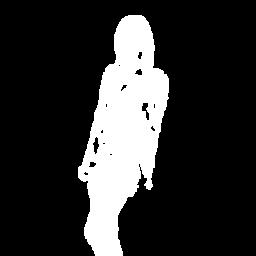

In [33]:
idx = random.randint(0, len(high_ratio_objs))

exp_image_f = high_ratio_objs[idx]['mask_path']
exp_image = Image.open(os.path.join(ROOT_DIR, exp_image_f))
print(f"Mask SA ratio:   {high_ratio_objs[idx]['ratio']}")
display(exp_image)

### Calculating Bins

In [57]:
bins = create_even_bins(all_ratios, NUM_BINS)
for b in bins:
    print(f"Bin size:  {len(b)}")
    print(f"Min ratio:  {min(b)}")
    print(f"Max ratio:  {max(b)}\n")

Bin size:  2999
Min ratio:  0.0017667436489607307
Max ratio:  0.009765625

Bin size:  2999
Min ratio:  0.009765625
Max ratio:  0.0200958251953125

Bin size:  2999
Min ratio:  0.0200958251953125
Max ratio:  0.050507162534435254

Bin size:  2999
Min ratio:  0.0505218505859375
Max ratio:  0.208892822265625

Bin size:  2995
Min ratio:  0.2089691162109375
Max ratio:  1.4961995257991298



### Final Bin Sizes:
* 1: [0.001 - 0.01]
* 2: [0.01 - 0.05]
* 3: [0.05 - 0.2]
* 4: [0.2 - 0.5]
* 5: [0.5 - 1]

In [9]:
bin_size_dict = {
    '1': {'min': 0.0, 'max': 0.01},
    '2': {'min': 0.01, 'max': 0.05},
    '3': {'min': 0.05, 'max': 0.2},
    '4': {'min': 0.2, 'max': 0.5},
    '5': {'min': 0.5, 'max': 2},
}

In [10]:
for key, meta in data.items():
    for obj in meta['objects']:
        ratio = obj['ratio']
        sa_cat = None
        for k, bounds in bin_size_dict.items():
            if ratio >= bounds['min'] and ratio < bounds['max']:
                sa_cat = k
                
        try:
            assert sa_cat is not None
        except:
            ipdb.set_trace()
        obj['SA_change_category'] = sa_cat


In [11]:
data[list(data.keys())[0]]

{'image_path': 'ADE20K_People_256/images/ADE_train_00020216.jpg',
 'entities': ['airlock', 'pipe', 'person'],
 'dataset': 'ADE20K',
 'objects': [{'id': 'ADE_train_00020216/instance_000_ADE_train_00020216',
   'mask_path': 'ADE20K_People_256/images/ADE_train_00020216/instance_000_ADE_train_00020216.png',
   'name': 'person',
   'ratio': 0.2905077977443204,
   'SA_change_category': '4'},
  {'id': 'ADE_train_00020216/instance_001_ADE_train_00020216',
   'mask_path': 'ADE20K_People_256/images/ADE_train_00020216/instance_001_ADE_train_00020216.png',
   'name': 'person',
   'ratio': 0.18749482848560065,
   'SA_change_category': '3'},
  {'id': 'ADE_train_00020216/instance_002_ADE_train_00020216',
   'mask_path': 'ADE20K_People_256/images/ADE_train_00020216/instance_002_ADE_train_00020216.png',
   'name': 'airlock',
   'ratio': 0.9625132660586766,
   'SA_change_category': '5'},
  {'id': 'ADE_train_00020216/instance_003_ADE_train_00020216',
   'mask_path': 'ADE20K_People_256/images/ADE_train_00

In [12]:
with open(METADATA, 'w') as jf:
    json.dump(data, jf)